# Parte 2: Redes neuronales en PyTorch

## Introducción

En este notebook se construye una red neuronal utilizando PyTorch para clasificar imágenes del conjunto de datos MNIST. Este conjunto contiene imágenes de dígitos escritos a mano, correspondientes a las clases del 0 al 9.

Se estudian la carga y transformación de los datos, la construcción de una red neuronal, el cálculo de sus salidas y la evaluación inicial de sus predicciones mediante una función de pérdida.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import torch

import matplotlib.pyplot as plt
from torchvision import datasets, transforms

## Carga y preparación de los datos

Las imágenes de MNIST se convierten en tensores mediante `transforms.ToTensor()`. Posteriormente, `transforms.Normalize((0.5,), (0.5,))` transforma sus valores para centrarlos aproximadamente alrededor de cero.

El `DataLoader` permite organizar las imágenes en lotes (*batches*), facilitando su procesamiento durante el entrenamiento y la evaluación del modelo.

En este ejercicio se inspeccionan las dimensiones de las imágenes, sus etiquetas y una representación visual para comprender cómo están almacenados los datos.

In [2]:
# Definir una transformación para normalizar los datos
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

# Descargar y cargar los datos de entrenamiento
trainset = datasets.MNIST(
    'MNIST_data/',
    download=True,
    train=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True
)

# Descargar y cargar los datos de prueba
testset = datasets.MNIST(
    'MNIST_data/',
    download=True,
    train=False,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=True
)

In [3]:
dataiter = iter(trainloader)
images, labels = next(dataiter)

images.shape

torch.Size([64, 1, 28, 28])

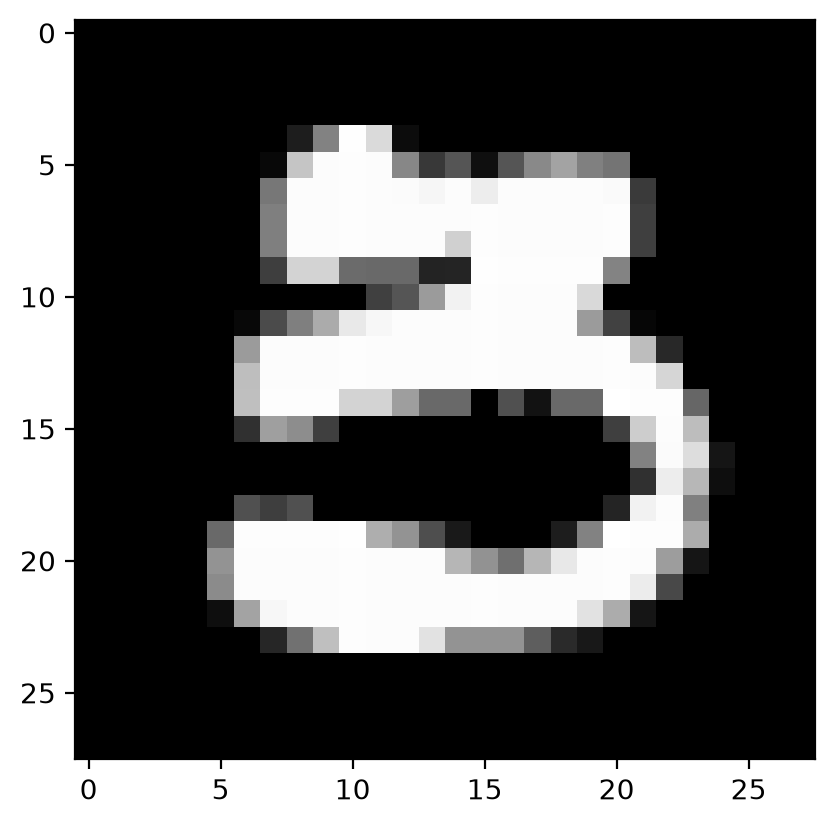

In [4]:
plt.imshow(images[0].numpy().squeeze(), cmap='gray')
plt.show()

In [5]:
labels[0]

tensor(3)

In [6]:
images = images.view(images.shape[0], -1)
images.shape

torch.Size([64, 784])

## Construcción de la red neuronal

La arquitectura utilizada es una red neuronal totalmente conectada con tres capas lineales:

- **Entrada:** 784 características, correspondientes a los píxeles de una imagen de 28 × 28.
- **Primera capa oculta:** 128 neuronas, seguida de la función de activación ReLU.
- **Segunda capa oculta:** 64 neuronas, también seguida de ReLU.
- **Salida:** 10 valores, uno por cada dígito posible.

La función ReLU introduce no linealidad en la red. La última capa produce los valores utilizados para determinar cuál de las diez clases es la más probable.

In [7]:
import torch.nn as nn

model = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

model

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=10, bias=True)
)

## Propagación hacia adelante

Durante la propagación hacia adelante (*forward pass*), las imágenes se procesan a través de las capas de la red para obtener una salida.

Antes de entrar al modelo, cada imagen se reorganiza de una matriz de 28 × 28 píxeles a un vector de 784 elementos.

Los valores de salida, llamados *logits*, son puntuaciones sin normalizar para cada clase. La función `torch.softmax()` permite convertirlos en valores que suman uno y pueden interpretarse como probabilidades estimadas por el modelo.

Finalmente, `argmax()` identifica la clase con la puntuación más alta.

In [8]:
logits = model(images)
logits.shape

torch.Size([64, 10])

In [9]:
logits[0]

tensor([ 0.0154,  0.0435,  0.2355, -0.1520, -0.0918,  0.1197,  0.0228,  0.0735,
        -0.0547, -0.2484], grad_fn=<SelectBackward0>)

In [10]:
probabilities = torch.softmax(logits[0], dim=0)
probabilities

tensor([0.1010, 0.1039, 0.1259, 0.0855, 0.0908, 0.1122, 0.1018, 0.1071, 0.0942,
        0.0776], grad_fn=<SoftmaxBackward0>)

In [11]:
probabilities.argmax()

tensor(2)

## Función de pérdida y parámetros

La función `nn.CrossEntropyLoss()` mide la diferencia entre las puntuaciones del modelo y las etiquetas correctas. Un valor de pérdida menor indica que las predicciones se ajustan mejor a las etiquetas en ese lote, aunque por sí solo no garantiza una buena generalización.

También se examinan las dimensiones de los pesos y sesgos de la primera capa, el número total de parámetros entrenables y la propiedad `requires_grad`, que indica si un parámetro participa en el cálculo de gradientes.

Estos elementos permiten comprender cómo está representada internamente la red neuronal.

In [12]:
criterion = nn.CrossEntropyLoss()

In [13]:
loss = criterion(logits, labels)
loss

tensor(2.2701, grad_fn=<NllLossBackward0>)

In [14]:
model[0].weight.shape

torch.Size([128, 784])

In [15]:
model[0].bias.shape

torch.Size([128])

In [16]:
total_params = sum(p.numel() for p in model.parameters())
total_params

109386

In [17]:
model[0].weight.requires_grad

True

In [18]:
for name, param in model.named_parameters():
    print(name, param.shape)

0.weight torch.Size([128, 784])
0.bias torch.Size([128])
2.weight torch.Size([64, 128])
2.bias torch.Size([64])
4.weight torch.Size([10, 64])
4.bias torch.Size([10])


## Conclusiones

En este ejercicio se construyó una red neuronal para clasificar dígitos de MNIST utilizando PyTorch. Se estudiaron la preparación de los datos, las capas lineales, la función de activación ReLU, la propagación hacia adelante y la conversión de las salidas en probabilidades.

Además, se exploraron la función de pérdida y los parámetros del modelo. Estos conceptos sirven como base para la siguiente etapa, en la que se entrena la red neuronal y se evalúa su desempeño.